# Sepsis: компактный пример цензуры, интенсивностей и прогноза

CSV → `EventLog.prepare` → интервалы → train DFG → `ProcessModel` → NLL на holdout
и прогноз полного пути до Discharge. Основной пример работает без PM4Py и Graphviz.
Модель — независимые exponential clocks с выбором минимального времени; вероятности
следующего направления и времена отдельных часов различаются.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "dima/survpm/src/survpm").is_dir())
sys.path.insert(0, str(ROOT / "dima/survpm/src"))
from survpm import (EventLog, Network, ProcessModel, ExponentialTransitionModel,
                    ObjectStream, Simulator, Forecaster, discover,
                    DirectlyFollowsBackend, evaluate, compare, compare_networks)
from survpm import datasets
from survpm.log import censoring_summary
from survpm.viz import MatplotlibVisualizer
pd.set_option("display.precision", 4, "display.max_columns", 20)

## 1. Настройки своего CSV и чтение

В `MAPPING` указываются исходные имена колонок. Пример читает только события; при наличии
отдельных замеров передайте их в `EventLog`, а известный конец наблюдения — в `last_seen`
или `observation`. Здесь конец незавершённого наблюдения — последняя доступная запись.
Нельзя добавлять вымышленные дни последующего наблюдения.

In [2]:
LOG_PATH = ROOT / "Med_Eremina/Sepsis Cases - Event Log_grouped.csv"
CSV_SEP = ","
MAPPING = {"case_id": "case_id", "activity": "event_group", "timestamp": "time:timestamp"}
START, TERMINAL = "Registration", "Discharge"
# Для своего CSV измените также словарь состояний и правила подготовки.
STATE_VOCABULARY = ["Registration", "Examination", "Treatment", "Admission", "Discharge", "Return"]
REPEATS = "simultaneous"       # поздние повторы дают self-loop; также collapse / keep
MIN_DURATION_DAYS = 1 / 1440  # технический нижний порог: одна минута
TRAIN_RATIO = .75
SEED = 2026

In [3]:
raw_frame = pd.read_csv(LOG_PATH, sep=CSV_SEP, dtype=str, keep_default_na=False)
raw_log = EventLog.from_frame(raw_frame, MAPPING, static=[], dynamic=[])

def take_cases(log, ids):
    ids = set(ids)
    return EventLog(log.events.loc[log.events.case_id.isin(ids)].copy(),
                    log.cases.loc[log.cases.index.isin(ids)].copy(),
                    log.measurements.loc[log.measurements.case_id.isin(ids)].copy(),
                    log.last_seen.loc[log.last_seen.index.isin(ids)].copy(),
                    log.observation.loc[log.observation.case_id.isin(ids)].copy(), log.rules)

def split_cases(log, ratio=TRAIN_RATIO, seed=SEED):
    ids = log.events.case_id.drop_duplicates().to_numpy()
    ids = np.random.default_rng(seed).permutation(ids)
    boundary = int(len(ids) * ratio)
    parts = take_cases(log, ids[:boundary]), take_cases(log, ids[boundary:])
    assert set(parts[0].cases.index).isdisjoint(parts[1].cases.index)
    return parts

# Это структурный prior по заранее объявленному словарю, а не discovery по test.
# Он разрешает все направленные пары, включая петли, кроме исходов из терминала.
envelope = Network.from_edges([(s, d) for s in STATE_VOCABULARY if s != TERMINAL
                               for d in STATE_VOCABULARY], starts=[START], terminals=[TERMINAL])


rules = dict(starts=[START], terminals=[TERMINAL], repeats=REPEATS,
             min_duration=MIN_DURATION_DAYS)
log = raw_log.prepare(rules)
unknown = set(log.events.activity) - set(STATE_VOCABULARY)
assert not unknown, f"Добавьте состояния в явный словарь: {unknown}"
train, test = split_cases(log)
train_iv, test_iv = train.intervals(), test.intervals()
print("Объектов train/test:", len(train.cases), len(test.cases))
print("Событий train/test:", len(train.events), len(test.events))
display(log.observation.groupby(["event", "reason"]).size().rename("cases"))
display(train_iv.head())
# Фактическое время между последним состоянием и концом наблюдения, до численного floor.
last_entry = log.events.groupby("case_id").timestamp.max()
obs = log.observation.set_index("case_id")
actual_tail = ((obs.end - last_entry) / pd.Timedelta(days=1)).loc[obs.event.eq(0)]
print("Незавершённых объектов:", len(actual_tail),
      "; с положительным фактическим хвостом:", int(actual_tail.gt(0).sum()))
display(censoring_summary(train_iv))

Объектов train/test: 787 263
Событий train/test: 6225 2100
Незавершённых объектов: 268 ; с положительным фактическим хвостом: 0


/Users/dimonzhi/Documents/proga/SurvivalProcessMining/dima/survpm/src/survpm/features.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  times = pd.concat([self.events[["case_id", "timestamp"]], self.measurements[["case_id", "timestamp"]]])
/Users/dimonzhi/Documents/proga/SurvivalProcessMining/dima/survpm/src/survpm/features.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  times = pd.concat([self.events[["case_id", "timestamp"]], self.measurements[["case_id", "timestamp"]]])
/Users/dimonzh

event  reason
0      lost      268
1                782
Name: cases, dtype: int64

,case_id,src,dst,duration,observed,reason,enter
0,A,Registration,Examination,0.0079,True,,2014-10-22 09:15:41+00:00
1,A,Examination,Treatment,0.1089,True,,2014-10-22 09:27:00+00:00
2,A,Treatment,Admission,0.0066,True,,2014-10-22 12:03:47+00:00
3,A,Admission,Examination,1.7824,True,,2014-10-22 12:13:19+00:00
4,A,Examination,Examination,2.0000,True,,2014-10-24 07:00:00+00:00


,src,n_visits,n_completed,p_completed,q_censored,n_lost,q_lost
0,Admission,974,963,0.9887,0.0113,11,0.0113
1,Examination,2755,2661,0.9659,0.0341,94,0.0341
2,Registration,787,759,0.9644,0.0356,28,0.0356
3,Treatment,1127,1055,0.9361,0.0639,72,0.0639


## 2. Структура и параметры

DFG строится только на train. Для оценки объявлен полный направленный structural prior
по словарю состояний из настроек: он не использует рёбра test. Нет событий на train —
rate равен нулю. Поэтому prior позволяет описать неизвестное ребро, но не делает его
правдоподобие положительным. Для другого процесса задайте содержательную структуру.

`aware_rate` — интенсивность отдельного часа (1/день); `clock_mean_days = 1/rate`.
`p` — `rate/sum(rate)` среди выходов, `mean_days = 1/sum(rate)` — среднее минимума.
Цензура в таблице описывает прекращение записи и не является клиническим состоянием.
При нулевом фактическом хвосте цензуры различие aware/naive обусловлено только
техническим floor одной минуты. Этот порог применяется и к совпадающим timestamp.

In [4]:
found = discover(train, DirectlyFollowsBackend(starts=[START], terminals=[TERMINAL]))
print("Train DFG рёбер:", len(found.edges), "; разрешено prior:", len(envelope.edges))
print("Диагностика DFG:")
display(found.validate())
aware = ProcessModel(envelope).fit(train)
naive = ProcessModel(envelope).fit(train, use_censoring=False)
models = {"censor_aware": aware, "naive_completed_only": naive}
rates = aware.edges_table().rename(columns={"rate": "aware_rate"})
rates = rates.merge(naive.edges_table()[["src", "dst", "rate"]].rename(columns={"rate": "naive_rate"}),
                    on=["src", "dst"], validate="one_to_one")
rates["clock_mean_days"] = np.divide(1., rates.aware_rate,
    out=np.full(len(rates), np.inf), where=rates.aware_rate.to_numpy() > 0)
rates["rate_difference"] = rates.aware_rate - rates.naive_rate
display(rates)
print("Нулевых clocks:", int(rates.aware_rate.eq(0).sum()))
print("Максимальная разность rate:", rates.rate_difference.abs().max())

Train DFG рёбер: 15 ; разрешено prior: 30
Диагностика DFG:
Нулевых clocks: 15
Максимальная разность rate: 0.05583753192702545


/Users/dimonzhi/Documents/proga/SurvivalProcessMining/dima/survpm/src/survpm/features.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  times = pd.concat([self.events[["case_id", "timestamp"]], self.measurements[["case_id", "timestamp"]]])
/Users/dimonzhi/Documents/proga/SurvivalProcessMining/dima/survpm/src/survpm/features.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  times = pd.concat([self.events[["case_id", "timestamp"]], self.measurements[["case_id", "timestamp"]]])
/Users/dimonzh

,state,issue


,src,dst,n_completed,n_visits,aware_rate,p,mean_days,naive_rate,clock_mean_days,rate_difference
0,Registration,Registration,0,787,0.0000,0.0000,0.0186,0.0000,inf,0.0000e+00
1,Registration,Examination,569,787,40.3944,0.7497,0.0186,40.4503,0.0248,-5.5838e-02
2,Registration,Treatment,186,787,13.2045,0.2451,0.0186,13.2228,0.0757,-1.8253e-02
3,Registration,Admission,4,787,0.2840,0.0053,0.0186,0.2844,3.5215,-3.9253e-04
4,Registration,Discharge,0,787,0.0000,0.0000,0.0186,0.0000,inf,0.0000e+00
5,Registration,Return,0,787,0.0000,0.0000,0.0186,0.0000,inf,0.0000e+00
6,Examination,Registration,0,2755,0.0000,0.0000,1.1846,0.0000,inf,0.0000e+00
7,Examination,Examination,1291,2755,0.4096,0.4852,1.1846,0.4096,2.4416,-8.4820e-06
8,Examination,Treatment,524,2755,0.1662,0.1969,1.1846,0.1662,6.0155,-3.4428e-06
9,Examination,Admission,378,2755,0.1199,0.1421,1.1846,0.1199,8.3389,-2.4835e-06


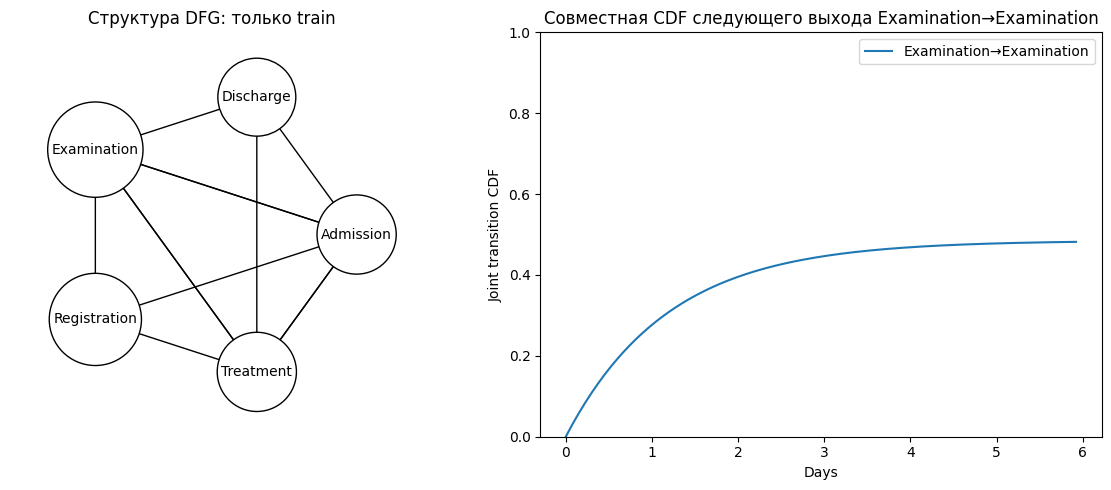

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
found.plot(ax=axes[0])
axes[0].set_title("Структура DFG: только train")
# Наиболее частый train-переход; выбор не использует test.
edge = tuple(rates.sort_values("n_completed", ascending=False).iloc[0][["src", "dst"]])
viz = MatplotlibVisualizer()
total = sum(aware.transition_parameters(edge[0]).values())
times = np.linspace(0, 5/total, 160)
viz.plot_edge_curves(aware, edge, times, ax=axes[1])
axes[1].set_title(f"Совместная CDF следующего выхода {edge[0]}→{edge[1]}")
axes[1].legend()
fig.tight_layout()

## 3. Оценка на всех отложенных объектах

Разделение случайное и по целым объектам; это не проверка переноса во времени.
NLL учитывает все test-интервалы с цензурой. `inf` при нулевом train-rate наблюдаемого
перехода — содержательный результат, а не повод отфильтровать тест.

In [6]:
# Проверяем весь holdout: ни строки, ни целые объекты не исключаем.
positive_train_edges = {e for e, rate in aware.transitions.rates.items() if rate > 0}
observed_test = test_iv.loc[test_iv.observed, ["case_id", "src", "dst"]].copy()
observed_test["zero_train_rate"] = [
    (s, d) not in positive_train_edges for s, d in observed_test[["src", "dst"]].itertuples(index=False, name=None)]
unseen = observed_test.loc[observed_test.zero_train_rate]
print("Переходов с rate=0 на test:", len(unseen),
      "; затронуто целых объектов:", unseen.case_id.nunique(), "из", len(test.cases))
display(unseen.groupby(["src", "dst"]).size().rename("test_count").reset_index())
full_holdout = compare(models, test, metrics=["nll"])
display(full_holdout)
assert test_iv.case_id.nunique() == len(test.cases)

Переходов с rate=0 на test: 0 ; затронуто целых объектов: 0 из 263


/Users/dimonzhi/Documents/proga/SurvivalProcessMining/dima/survpm/src/survpm/features.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  times = pd.concat([self.events[["case_id", "timestamp"]], self.measurements[["case_id", "timestamp"]]])
/Users/dimonzhi/Documents/proga/SurvivalProcessMining/dima/survpm/src/survpm/features.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  times = pd.concat([self.events[["case_id", "timestamp"]], self.measurements[["case_id", "timestamp"]]])


,src,dst,test_count


,model,metric,value
0,censor_aware,nll_per_interval,1.0628
1,censor_aware,nll_per_trace,7.6777
2,naive_completed_only,nll_per_interval,1.0627
3,naive_completed_only,nll_per_trace,7.6776


## 4. Прогноз полного пути

Только история выбранного test-объекта на момент первой регистрации доступна прогнозу.
По 300 Monte Carlo путям получаем survival и restricted mean за 30 дней;
ограниченное среднее не равно безусловному среднему времени выписки.
Это иллюстрация модели журнала, а не медицинская рекомендация или проверка калибровки.

/Users/dimonzhi/Documents/proga/SurvivalProcessMining/dima/survpm/src/survpm/features.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  times = pd.concat([self.events[["case_id", "timestamp"]], self.measurements[["case_id", "timestamp"]]])
/Users/dimonzhi/Documents/proga/SurvivalProcessMining/dima/survpm/src/survpm/features.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  times = pd.concat([self.events[["case_id", "timestamp"]], self.measurements[["case_id", "timestamp"]]])


,horizon,survival,cdf
0,0.0,1.0000,0.0000
1,1.0,0.8800,0.1200
2,3.0,0.6833,0.3167
3,7.0,0.3767,0.6233
4,14.0,0.1133,0.8867
5,30.0,0.0200,0.9800


,restricted_mean_time,probability_unfinished
0,6.8634,0.02


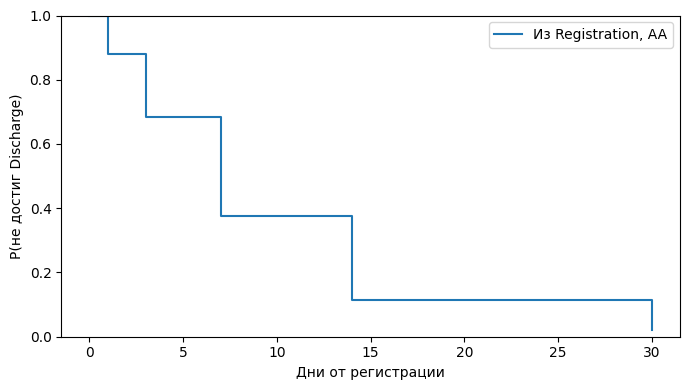

In [7]:
case_id = test.events.case_id.iloc[0]
entry = test.events.loc[test.events.case_id.eq(case_id), "timestamp"].min()
times = np.array([0., 1., 3., 7., 14., 30.])
forecaster = Forecaster(aware, n_paths=300, seed=42)
survival = forecaster.survival(test, entry, times, case_id=case_id)
display(survival)
display(pd.DataFrame([forecaster.expected_time(test, entry, horizon=30., case_id=case_id)]))
fig, ax = plt.subplots(figsize=(7, 4))
ax.step(survival.horizon, survival.survival, where="post", label=f"Из Registration, {case_id}")
ax.set(xlabel="Дни от регистрации", ylabel="P(не достиг Discharge)", ylim=(0, 1))
ax.legend()
fig.tight_layout()

Ограничения: общий Petri net и параллелизм не моделируются; неизвестный follow-up восстановить
нельзя. Матplotlib показывает только топологию и согласованные min-time кривые. AIC между
разными семействами, сравнение с Inductive Miner и старый набор allmetrics здесь не заявляются.
Данные и результаты остаются в памяти; экспорт можно добавить отдельным явным действием.